#PREREQUISITES

Installing SDV Library which contains synthetic data tools.

In [27]:
!pip install -q sdv

Uploading the Auto MPG Dataset.

In [28]:
from google.colab import files
files.upload()

Saving auto-mpg.csv to auto-mpg (1).csv


{'auto-mpg (1).csv': b"mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name\r\n18,8,307,130,3504,12,70,1,chevrolet chevelle malibu\r\n15,8,350,165,3693,11.5,70,1,buick skylark 320\r\n18,8,318,150,3436,11,70,1,plymouth satellite\r\n16,8,304,150,3433,12,70,1,amc rebel sst\r\n17,8,302,140,3449,10.5,70,1,ford torino\r\n15,8,429,198,4341,10,70,1,ford galaxie 500\r\n14,8,454,220,4354,9,70,1,chevrolet impala\r\n14,8,440,215,4312,8.5,70,1,plymouth fury iii\r\n14,8,455,225,4425,10,70,1,pontiac catalina\r\n15,8,390,190,3850,8.5,70,1,amc ambassador dpl\r\n15,8,383,170,3563,10,70,1,dodge challenger se\r\n14,8,340,160,3609,8,70,1,plymouth 'cuda 340\r\n15,8,400,150,3761,9.5,70,1,chevrolet monte carlo\r\n14,8,455,225,3086,10,70,1,buick estate wagon (sw)\r\n24,4,113,95,2372,15,70,3,toyota corona mark ii\r\n22,6,198,95,2833,15.5,70,1,plymouth duster\r\n18,6,199,97,2774,15.5,70,1,amc hornet\r\n21,6,200,85,2587,16,70,1,ford maverick\r\n27,4,97,88,2130,14.5,70,3,datsun pl51

In [29]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import ks_2samp
from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid")

Importing all of the required Libraries and Tools required.

#LOADING AND CLEANING

**Dataset:** Auto MPG UCI Machine Learning Respository

**Target Variable:** mpg

**Reason:** Continous numerical values measured in real cars

In [30]:
df = pd.read_csv("auto-mpg.csv")
print(df.shape)
print(df.dtypes)
df.head()

(398, 9)
mpg             float64
cylinders         int64
displacement    float64
horsepower       object
weight            int64
acceleration    float64
model year        int64
origin            int64
car name         object
dtype: object


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


Cleaning the Dataset.

In [31]:
df = df.rename(columns={"model year": "model_year", "car name": "car_name"})

# errors="coerce" turns any non-number (like "?") into NaN (a proper "missing" marker)
df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")
print(df.isna().sum())

df = df.dropna().reset_index(drop=True)
df = df.drop(columns=["car_name"])   # text names are unique per car, useless for regression
print(df.shape)                       # expect (392, 8)

TARGET = "mpg"
FEATURES = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
synth_cols = FEATURES + [TARGET]

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64
(392, 8)


#Exploratory Data Analysis


Structure and Distribution

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           392 non-null    float64
 1   cylinders     392 non-null    int64  
 2   displacement  392 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        392 non-null    int64  
 5   acceleration  392 non-null    float64
 6   model_year    392 non-null    int64  
 7   origin        392 non-null    int64  
dtypes: float64(4), int64(4)
memory usage: 24.6 KB


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,23.445918,5.471939,194.411990,104.469388,2977.584184,15.541327,75.979592,1.576531
std,7.805007,1.705783,104.644004,38.491160,849.402560,2.758864,3.683737,0.805518
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.000000,4.000000,105.000000,75.000000,2225.250000,13.775000,73.000000,1.000000
50%,22.750000,4.000000,151.000000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,275.750000,126.000000,3614.750000,17.025000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


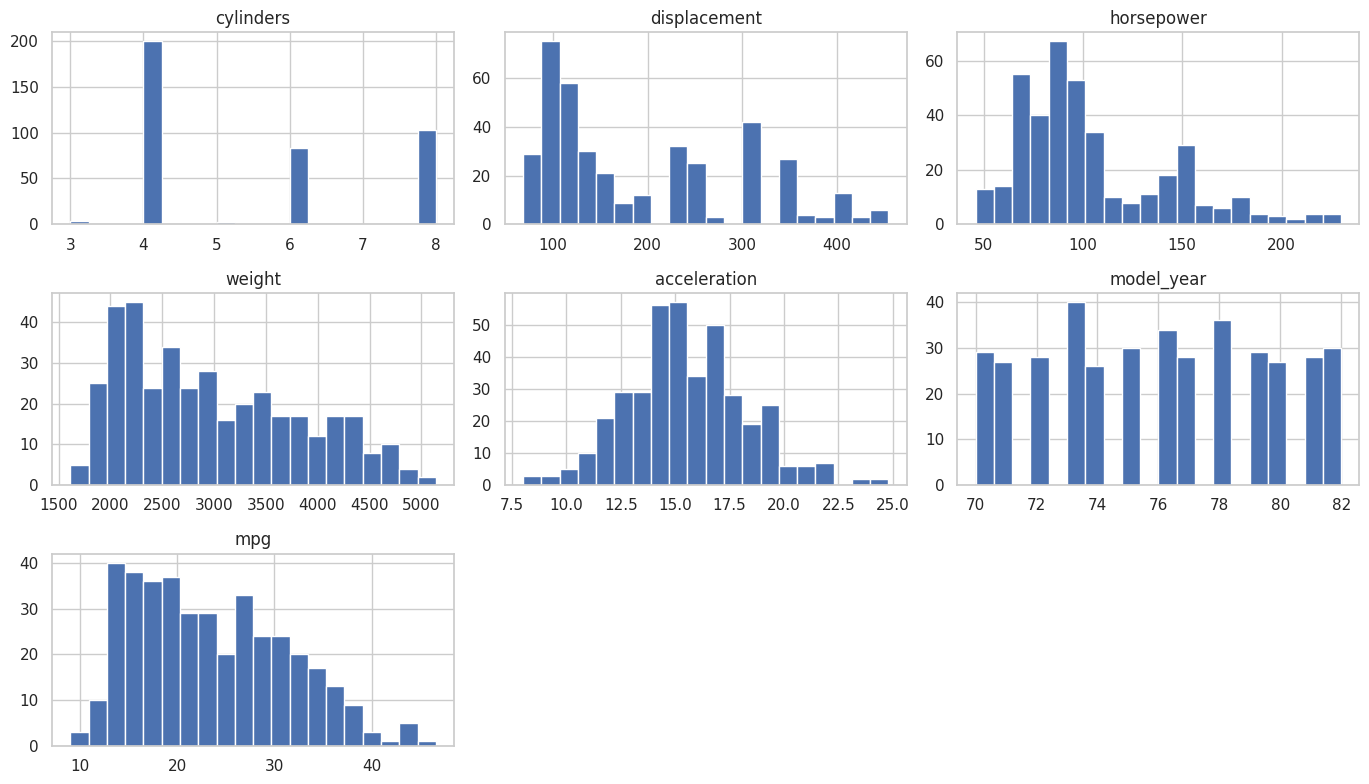

In [32]:
df.info()
display(df.describe())

df[synth_cols].hist(bins=20, figsize=(14, 8))
plt.tight_layout(); plt.show()

Checking for Outliers

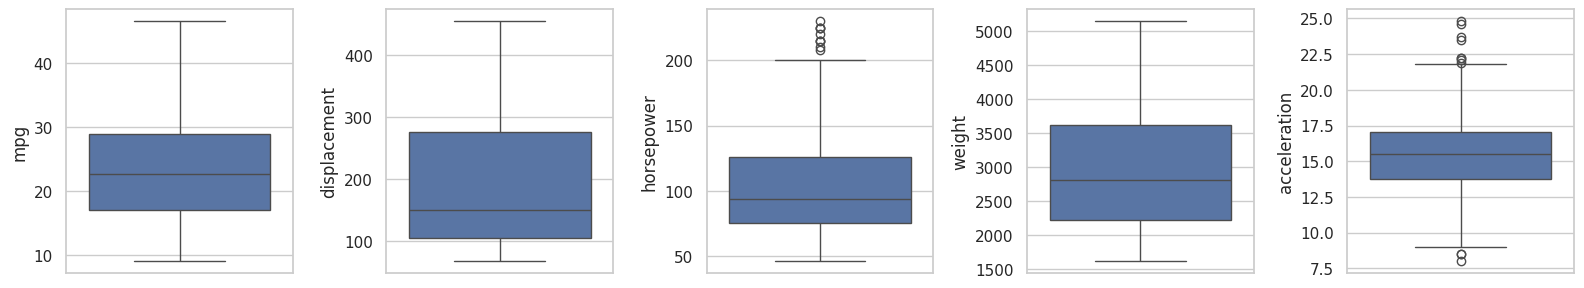

mpg: 0 outliers
displacement: 0 outliers
horsepower: 10 outliers
weight: 0 outliers
acceleration: 11 outliers


In [33]:
num_cols = ["mpg", "displacement", "horsepower", "weight", "acceleration"]

fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax)
plt.tight_layout(); plt.show()

for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    print(f"{c}: {n} outliers")

Correlation Heatmap & Pairplot


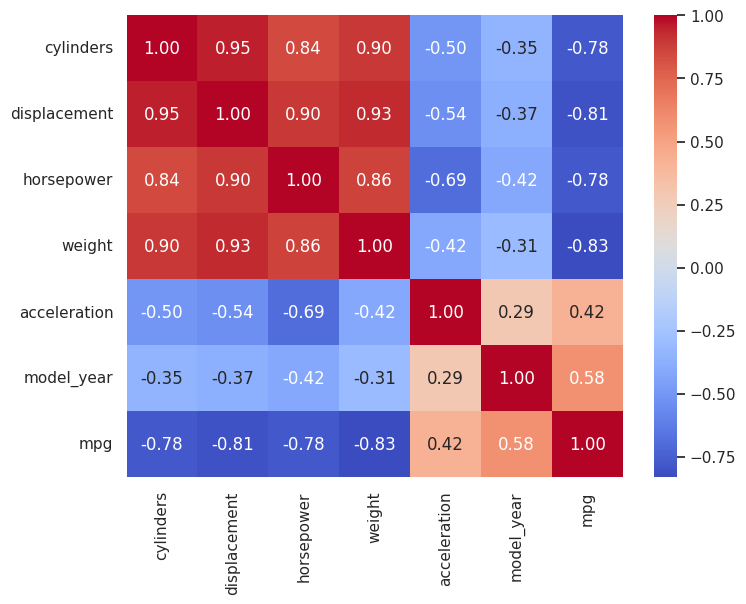

In [34]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[synth_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

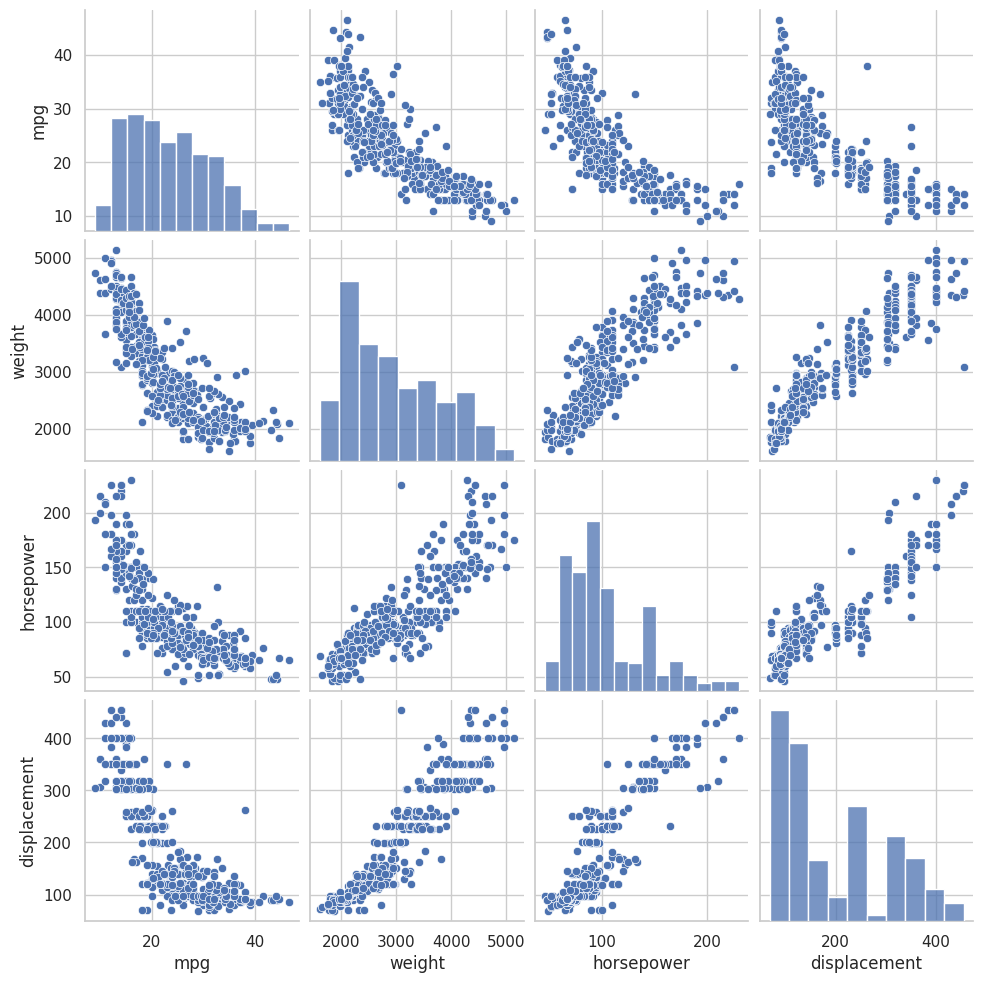

In [35]:
sns.pairplot(df[["mpg", "weight", "horsepower", "displacement"]])
plt.show()

Checking for a Curve

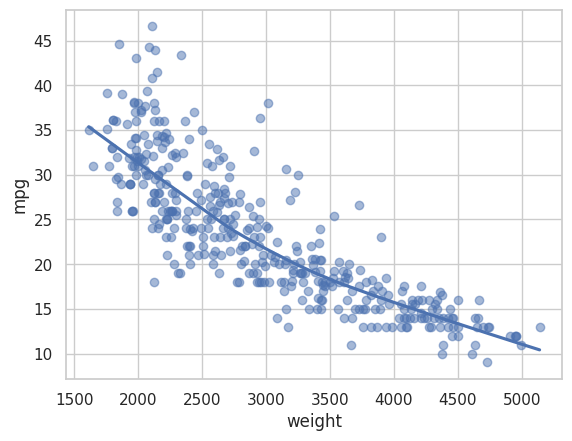

In [36]:
sns.regplot(x="weight", y="mpg", data=df, lowess=True, scatter_kws={"alpha": 0.5})
plt.show()

Weight, horsepower, and displacement are strongly negatively correlated with mpg. They are also strongly correlated with each other (multicollinearity). The weight vs mpg relationship bends instead of being straight, which is why polynomial regression should be applied to this dataset.

#Splitting the Dataset into Train/Test split

In [37]:
train_real, test_real = train_test_split(df, test_size=0.2, random_state=42)
train_real = train_real.reset_index(drop=True)
test_real = test_real.reset_index(drop=True)

print("Train:", train_real.shape, " Test:", test_real.shape)

Train: (313, 8)  Test: (79, 8)


This split was done before any synthetic was created to prevent leakage.

A scoring helper

In [38]:
results = []
fitted = {}

def evaluate(setup, name, model, cols, train_df):
    m = clone(model)                          # fresh copy, so models never share state
    m.fit(train_df[cols], train_df[TARGET])
    tr_pred = m.predict(train_real[cols])
    te_pred = m.predict(test_real[cols])
    mse = mean_squared_error(test_real[TARGET], te_pred)
    results.append({
        "Setup": setup, "Model": name,
        "Train R2": r2_score(train_real[TARGET], tr_pred),
        "Test R2": r2_score(test_real[TARGET], te_pred),
        "Test MSE": mse, "Test RMSE": np.sqrt(mse),
        "Test MAE": mean_absolute_error(test_real[TARGET], te_pred),
    })
    fitted[(setup, name)] = m

It scores every model the same way, so the comparison is fair. Train R² is measured on the real training rows only, so the overfitting gap is comparable across setups.

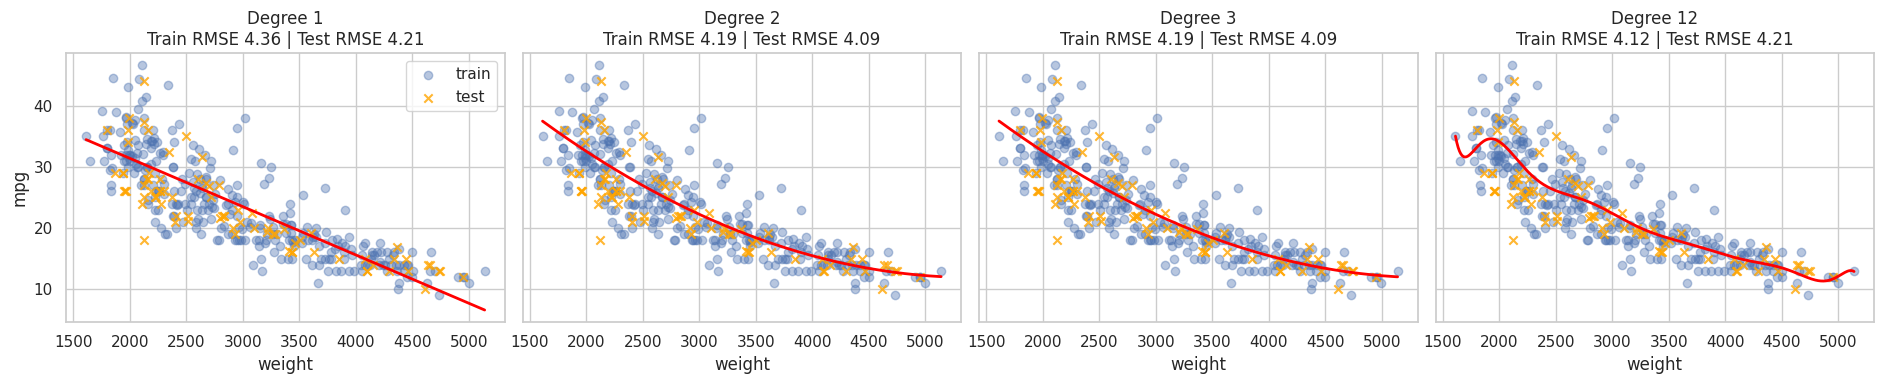

In [39]:
from sklearn.model_selection import cross_val_score

X_COL = "weight"

def poly_model(degree):
    # Scale first so high powers stay numerically stable, then add polynomial terms
    return Pipeline([
        ("scale", StandardScaler()),
        ("poly", PolynomialFeatures(degree, include_bias=False)),
        ("lr", LinearRegression()),
    ])

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

degrees_to_show = [1, 2, 3, 12]
x_grid = pd.DataFrame({X_COL: np.linspace(df[X_COL].min(), df[X_COL].max(), 300)})

fig, axes = plt.subplots(1, 4, figsize=(19, 4), sharey=True)
for ax, d in zip(axes, degrees_to_show):
    m = poly_model(d).fit(train_real[[X_COL]], train_real[TARGET])
    tr = rmse(train_real[TARGET], m.predict(train_real[[X_COL]]))
    te = rmse(test_real[TARGET], m.predict(test_real[[X_COL]]))

    ax.scatter(train_real[X_COL], train_real[TARGET], alpha=0.4, label="train")
    ax.scatter(test_real[X_COL], test_real[TARGET], alpha=0.8, color="orange", marker="x", label="test")
    ax.plot(x_grid[X_COL], m.predict(x_grid), color="red", lw=2)
    ax.set_title(f"Degree {d}\nTrain RMSE {tr:.2f} | Test RMSE {te:.2f}")
    ax.set_xlabel(X_COL)
axes[0].set_ylabel("mpg")
axes[0].legend()
plt.tight_layout(); plt.show()

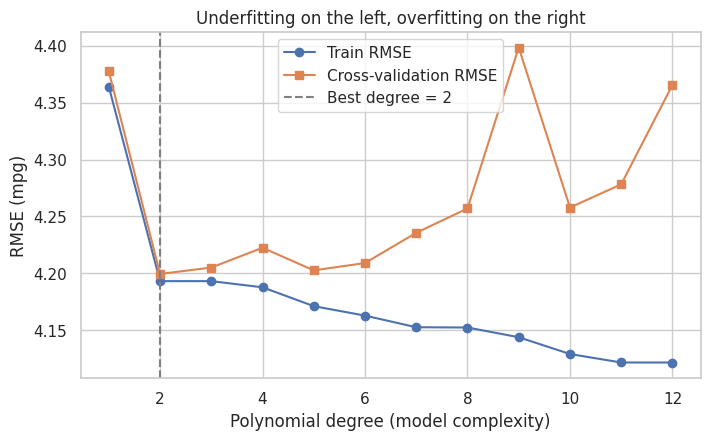

Chosen degree: 2
Test RMSE at that degree: 4.085


In [40]:
degrees = list(range(1, 13))
train_rmse, cv_rmse = [], []

for d in degrees:
    m = poly_model(d).fit(train_real[[X_COL]], train_real[TARGET])
    train_rmse.append(rmse(train_real[TARGET], m.predict(train_real[[X_COL]])))

    cv_mse = -cross_val_score(poly_model(d), train_real[[X_COL]], train_real[TARGET],
                              cv=5, scoring="neg_mean_squared_error").mean()
    cv_rmse.append(np.sqrt(cv_mse))

best_d = degrees[int(np.argmin(cv_rmse))]

plt.figure(figsize=(8, 4.5))
plt.plot(degrees, train_rmse, "o-", label="Train RMSE")
plt.plot(degrees, cv_rmse, "s-", label="Cross-validation RMSE")
plt.axvline(best_d, color="gray", ls="--", label=f"Best degree = {best_d}")
plt.xlabel("Polynomial degree (model complexity)")
plt.ylabel("RMSE (mpg)")
plt.title("Underfitting on the left, overfitting on the right")
plt.legend(); plt.show()

# The test set is used only once, after the degree was chosen by cross-validation
final = poly_model(best_d).fit(train_real[[X_COL]], train_real[TARGET])
print(f"Chosen degree: {best_d}")
print(f"Test RMSE at that degree: {rmse(test_real[TARGET], final.predict(test_real[[X_COL]])):.3f}")

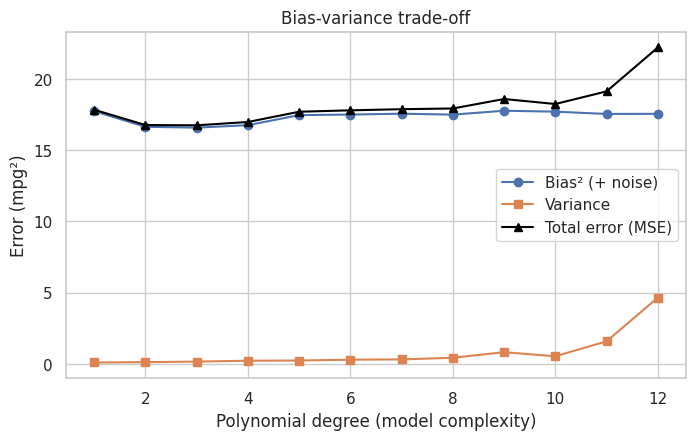

,Degree,Bias2,Variance,Total MSE
0,1,17.746,0.100,17.846
1,2,16.649,0.123,16.772
2,3,16.590,0.163,16.754
3,4,16.763,0.224,16.988
4,5,17.469,0.238,17.707
5,6,17.509,0.297,17.806
6,7,17.568,0.318,17.885
7,8,17.504,0.431,17.936
8,9,17.777,0.823,18.600
9,10,17.712,0.537,18.249


In [41]:
B = 200
rng = np.random.default_rng(42)
n = len(train_real)
X_te = test_real[[X_COL]]
y_te = test_real[TARGET].values

bias2_list, var_list, total_list = [], [], []

for d in degrees:
    preds = np.zeros((B, len(test_real)))
    for b in range(B):
        idx = rng.integers(0, n, n)                  # resample rows with replacement
        sample = train_real.iloc[idx]
        m = poly_model(d).fit(sample[[X_COL]], sample[TARGET])
        preds[b] = m.predict(X_te)

    mean_pred = preds.mean(axis=0)
    bias2_list.append(np.mean((mean_pred - y_te) ** 2))   # how far the average model is off
    var_list.append(np.mean(preds.var(axis=0)))           # how much the models disagree
    total_list.append(np.mean((preds - y_te) ** 2))       # equals bias² + variance

plt.figure(figsize=(8, 4.5))
plt.plot(degrees, bias2_list, "o-", label="Bias² (+ noise)")
plt.plot(degrees, var_list, "s-", label="Variance")
plt.plot(degrees, total_list, "^-", color="black", label="Total error (MSE)")
plt.xlabel("Polynomial degree (model complexity)")
plt.ylabel("Error (mpg²)")
plt.title("Bias-variance trade-off")
plt.legend(); plt.show()

bv = pd.DataFrame({"Degree": degrees, "Bias2": bias2_list,
                   "Variance": var_list, "Total MSE": total_list}).round(3)
display(bv)

**Tuning a Polynomial + Ridge Model**


*   Polynomial features let a line bend.
*   Ridge is a penalty on large coefficients. It solves the problem of polynomial models going wild and overfitting.
*   GridSearchCV tries every setting combination with 5-fold cross-validation and keeps the best.



In [42]:
pipe = Pipeline([
    ("poly", PolynomialFeatures(include_bias=False)),
    ("scale", StandardScaler()),
    ("ridge", Ridge()),
])
param_grid = {"poly__degree": [1, 2, 3], "ridge__alpha": [0.01, 0.1, 1, 10, 100]}

grid = GridSearchCV(pipe, param_grid, cv=5, scoring="neg_mean_squared_error")
grid.fit(train_real[FEATURES], train_real[TARGET])

print("Best settings:", grid.best_params_)
print("Best CV MSE:", -grid.best_score_)

Best settings: {'poly__degree': 3, 'ridge__alpha': 0.1}
Best CV MSE: 8.303392531439842


We tune only once, on real data only. If we tuned on real + synthetic data, the validation folds would contain synthetic copies of the real rows being validated, which would inflate the scores.

Defining all four models and scoring them

In [43]:
models = {
    "Simple Linear (weight)": (LinearRegression(), ["weight"]),
    "Poly deg 2 (weight)": (Pipeline([
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("lr", LinearRegression())]), ["weight"]),
    "Multiple Linear (6 features)": (Pipeline([
        ("scale", StandardScaler()), ("lr", LinearRegression())]), FEATURES),
    "Tuned Poly+Ridge (6 features)": (grid.best_estimator_, FEATURES),
}

for name, (model, cols) in models.items():
    evaluate("Real only", name, model, cols, train_real)

display(pd.DataFrame(results).round(3))

,Setup,Model,Train R2,Test R2,Test MSE,Test RMSE,Test MAE
0,Real only,Simple Linear (weight),0.698,0.653,17.693,4.206,3.464
1,Real only,Poly deg 2 (weight),0.721,0.673,16.689,4.085,3.138
2,Real only,Multiple Linear (6 features),0.811,0.794,10.502,3.241,2.504
3,Real only,Tuned Poly+Ridge (6 features),0.898,0.868,6.713,2.591,1.808


**Justification for each model:**
* Simple linear is the baseline.
* Polynomial on weight tests the curve you saw in EDA.
* Multiple linear uses all the information.
* Tuned poly + ridge handles the bending and the correlated features.

In [44]:
from sdv.single_table import GaussianCopulaSynthesizer

# Metadata tells SDV what each column is (numbers, categories, etc.)
try:
    from sdv.metadata import Metadata
    metadata = Metadata.detect_from_dataframe(train_real[synth_cols], table_name="auto")
except ImportError:                        # older SDV versions
    from sdv.metadata import SingleTableMetadata
    metadata = SingleTableMetadata()
    metadata.detect_from_dataframe(train_real[synth_cols])

synthesizer = GaussianCopulaSynthesizer(metadata)
synthesizer.fit(train_real[synth_cols])           # learns from TRAIN rows only

synthetic_raw = synthesizer.sample(num_rows=3000)
print(synthetic_raw.shape)
synthetic_raw.head()

/usr/local/lib/python3.13/dist-packages/sdv/single_table/base.py:139: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(


(3000, 7)


,cylinders,displacement,horsepower,weight,acceleration,model_year,mpg
0,8,238.0,153.0,4036,12.8,77,16.8
1,4,261.0,76.0,2161,15.1,76,31.6
2,4,104.0,78.0,2367,15.4,81,27.9
3,8,116.0,112.0,2477,9.6,74,30.1
4,6,156.0,107.0,2697,16.7,72,16.0


#Cleaning synthetic rows

In [45]:
def clean_synthetic(raw, ref):
    s = raw[synth_cols].astype(float).copy()

    # cylinders only takes values that exist in real data (3, 4, 5, 6, 8): snap to the nearest
    valid_cyl = np.sort(ref["cylinders"].unique()).astype(float)
    s["cylinders"] = s["cylinders"].apply(lambda v: valid_cyl[np.abs(valid_cyl - v).argmin()])

    s["model_year"] = s["model_year"].round()
    s["weight"] = s["weight"].round()

    # clip every column into the real min-max range (this also removes negatives)
    for c in synth_cols:
        s[c] = s[c].clip(ref[c].min(), ref[c].max())

    s = s.dropna()
    return s.astype(ref[synth_cols].dtypes.to_dict()).reset_index(drop=True)

synthetic = clean_synthetic(synthetic_raw, train_real)
print(synthetic.shape)

# How many synthetic rows are exact copies of a real row?
copies = synthetic.merge(train_real[synth_cols].drop_duplicates(), how="inner", on=synth_cols)
print("Exact copies of real rows:", len(copies))

(3000, 7)
Exact copies of real rows: 0


**Check synthetic data quality**

In [46]:
compare = pd.concat({
    "real": train_real[synth_cols].describe().T[["mean", "std", "min", "max"]],
    "synthetic": synthetic[synth_cols].describe().T[["mean", "std", "min", "max"]],
}, axis=1).round(2)
display(compare)

real                         synthetic                  \
                 mean     std     min     max      mean     std     min   
cylinders        5.48    1.70     3.0     8.0      5.41    1.68     3.0   
displacement   195.52  103.77    70.0   455.0    205.24  117.87    70.0   
horsepower     104.59   38.28    46.0   230.0    103.64   36.66    46.0   
weight        2986.12  841.13  1613.0  5140.0   3001.90  818.60  1613.0   
acceleration    15.54    2.82     8.0    24.8     15.62    2.76     8.2   
model_year      76.21    3.63    70.0    82.0     76.33    3.71    70.0   
mpg             23.60    7.96     9.0    46.6     23.72    7.76     9.9   

                      
                 max  
cylinders        8.0  
displacement   455.0  
horsepower     230.0  
weight        5140.0  
acceleration    24.8  
model_year      82.0  
mpg             46.6

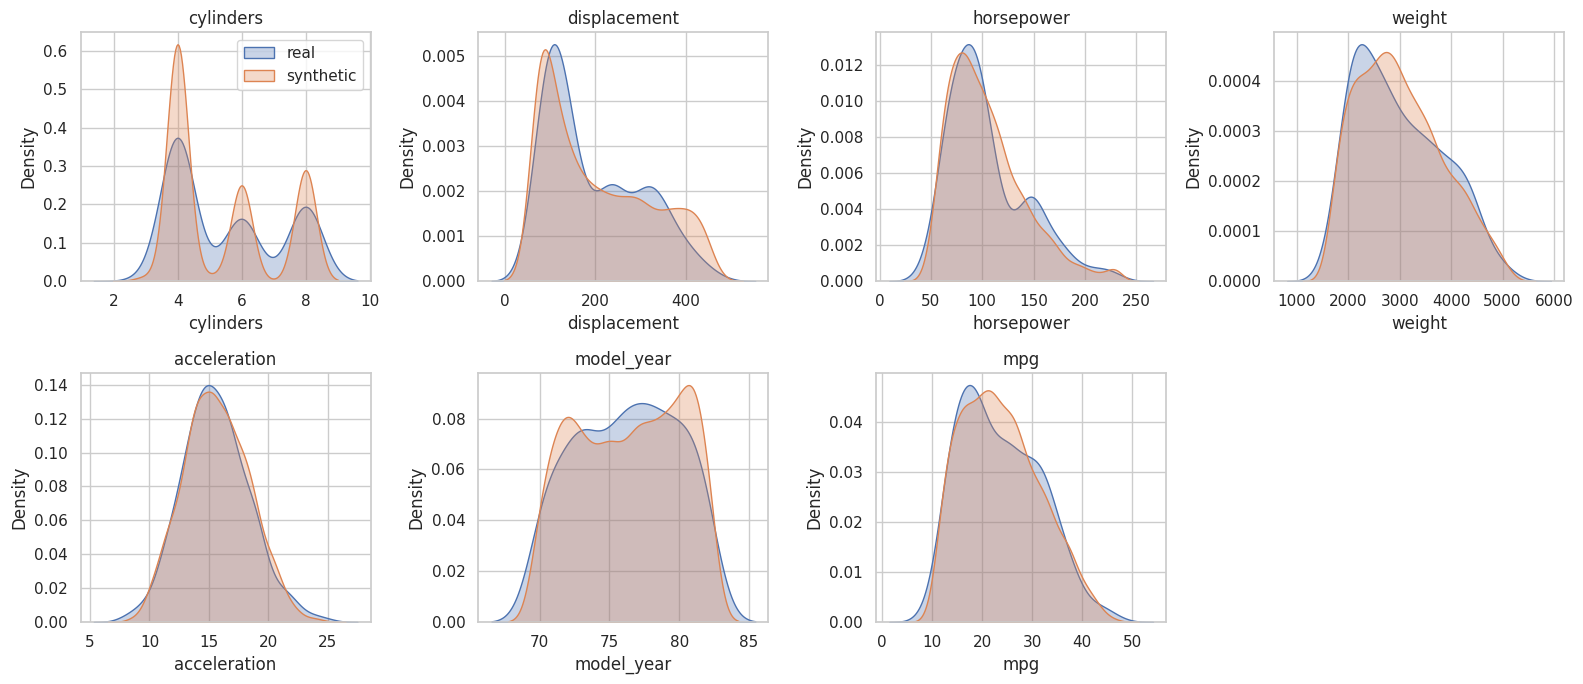

In [47]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), synth_cols):
    sns.kdeplot(train_real[c], ax=ax, label="real", fill=True, alpha=0.3)
    sns.kdeplot(synthetic[c], ax=ax, label="synthetic", fill=True, alpha=0.3)
    ax.set_title(c)
axes.ravel()[0].legend()
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

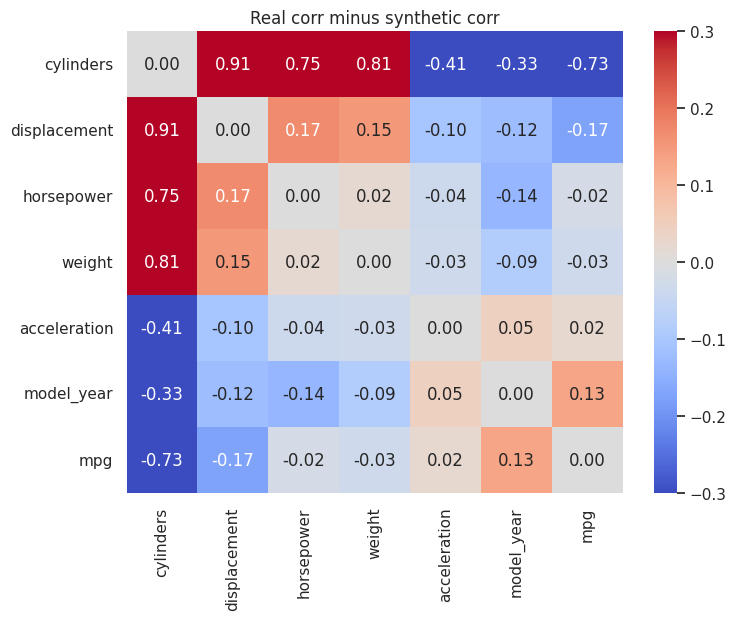

In [48]:
diff = train_real[synth_cols].corr() - synthetic[synth_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(diff, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-0.3, vmax=0.3)
plt.title("Real corr minus synthetic corr")
plt.show()

In [49]:
for c in synth_cols:
    d = ks_2samp(train_real[c], synthetic[c]).statistic
    print(f"{c:14s} KS D = {d:.3f}")

cylinders      KS D = 0.022
displacement   KS D = 0.136
horsepower     KS D = 0.063
weight         KS D = 0.056
acceleration   KS D = 0.042
model_year     KS D = 0.037
mpg            KS D = 0.056


**Train on real + synthetic and compare**

Augmented training size: (3313, 7)


,Setup,Model,Train R2,Test R2,Test MSE,Test RMSE,Test MAE
0,Real only,Simple Linear (weight),0.698,0.653,17.693,4.206,3.464
1,Real only,Poly deg 2 (weight),0.721,0.673,16.689,4.085,3.138
2,Real only,Multiple Linear (6 features),0.811,0.794,10.502,3.241,2.504
3,Real only,Tuned Poly+Ridge (6 features),0.898,0.868,6.713,2.591,1.808
4,Real + Synthetic,Simple Linear (weight),0.697,0.651,17.798,4.219,3.501
5,Real + Synthetic,Poly deg 2 (weight),0.719,0.663,17.217,4.149,3.234
6,Real + Synthetic,Multiple Linear (6 features),0.799,0.780,11.222,3.350,2.607
7,Real + Synthetic,Tuned Poly+Ridge (6 features),0.857,0.835,8.424,2.902,2.096


Setup,Real + Synthetic,Real only
Model,,
Multiple Linear (6 features),3.350,3.241
Poly deg 2 (weight),4.149,4.085
Simple Linear (weight),4.219,4.206
Tuned Poly+Ridge (6 features),2.902,2.591


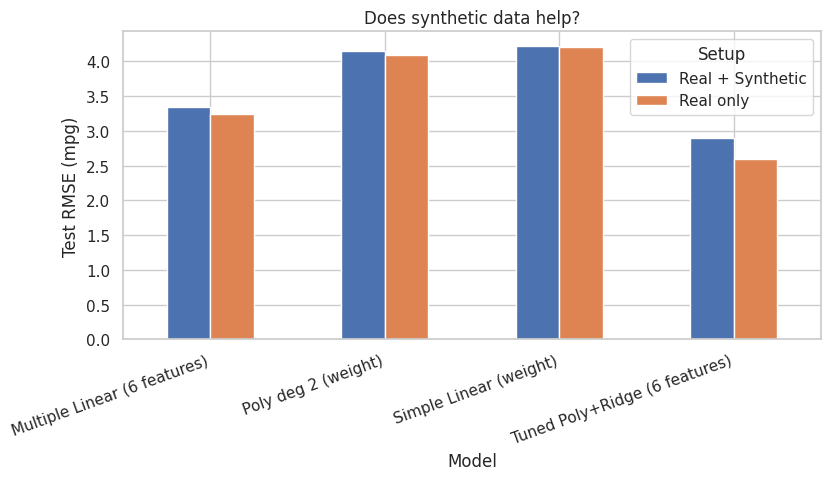

In [50]:
train_aug = pd.concat([train_real[synth_cols], synthetic], ignore_index=True)
print("Augmented training size:", train_aug.shape)

for name, (model, cols) in models.items():
    evaluate("Real + Synthetic", name, model, cols, train_aug)

res = pd.DataFrame(results).round(3)
display(res)

# Easier to read: test RMSE for each model in each setup
rmse_table = res.pivot(index="Model", columns="Setup", values="Test RMSE")
display(rmse_table)

rmse_table.plot(kind="bar", figsize=(9, 4))
plt.ylabel("Test RMSE (mpg)"); plt.xticks(rotation=20, ha="right")
plt.title("Does synthetic data help?"); plt.show()

RMSE            R2       
                                 mean    std   mean    std
Model           Synthetic rows                            
Multiple Linear 0               3.451  0.263  0.808  0.017
                300             3.488  0.216  0.803  0.016
                1000            3.592  0.219  0.791  0.015
                3000            3.668  0.230  0.783  0.017
Poly2 + Ridge   0               2.808  0.211  0.872  0.014
                300             2.947  0.193  0.860  0.013
                1000            3.055  0.244  0.849  0.017
                3000            3.174  0.411  0.836  0.038

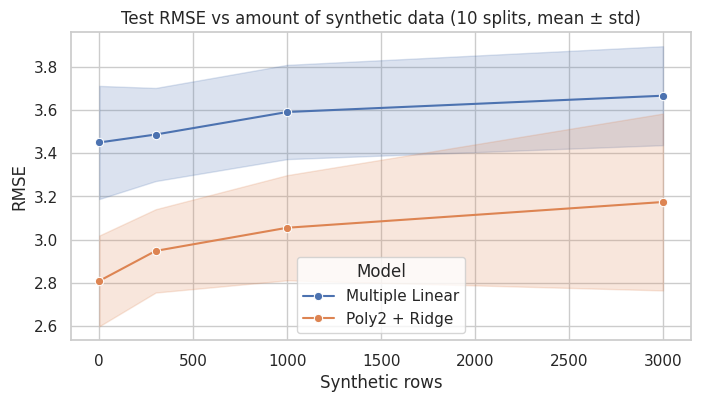

In [51]:
def make_fixed_models():
    return {
        "Multiple Linear": Pipeline([("scale", StandardScaler()), ("lr", LinearRegression())]),
        "Poly2 + Ridge": Pipeline([
            ("poly", PolynomialFeatures(2, include_bias=False)),
            ("scale", StandardScaler()), ("ridge", Ridge(alpha=1))]),
    }

rows = []
for seed in range(10):
    tr, te = train_test_split(df[synth_cols], test_size=0.2, random_state=seed)
    tr = tr.reset_index(drop=True)

    syn = GaussianCopulaSynthesizer(metadata)
    syn.fit(tr)                                  # train rows only, every time
    raw_all = syn.sample(num_rows=3000)

    for n_syn in [0, 300, 1000, 3000]:
        if n_syn == 0:
            train_set = tr
        else:
            train_set = pd.concat([tr, clean_synthetic(raw_all.iloc[:n_syn], tr)], ignore_index=True)

        for name, m in make_fixed_models().items():
            m.fit(train_set[FEATURES], train_set[TARGET])
            pred = m.predict(te[FEATURES])
            rows.append({"seed": seed, "Synthetic rows": n_syn, "Model": name,
                         "RMSE": np.sqrt(mean_squared_error(te[TARGET], pred)),
                         "R2": r2_score(te[TARGET], pred)})

rep = pd.DataFrame(rows)
display(rep.groupby(["Model", "Synthetic rows"])[["RMSE", "R2"]].agg(["mean", "std"]).round(3))

plt.figure(figsize=(8, 4))
sns.lineplot(data=rep, x="Synthetic rows", y="RMSE", hue="Model", marker="o", errorbar="sd")
plt.title("Test RMSE vs amount of synthetic data (10 splits, mean ± std)")
plt.show()

In [52]:
res = pd.DataFrame(results)

# 1) Real-only models: how good, and how much overfitting?
real_only = res[res["Setup"] == "Real only"].set_index("Model").copy()
real_only["R2 gap (train - test)"] = real_only["Train R2"] - real_only["Test R2"]
display(real_only[["Train R2", "Test R2", "R2 gap (train - test)", "Test RMSE"]].round(3))
print("Best model on the real test set:", real_only["Test RMSE"].idxmin())

# 2) Did synthetic data change the test RMSE? (negative change = improvement)
change = (rmse_table["Real + Synthetic"] - rmse_table["Real only"]).round(3)
print("\nChange in test RMSE after adding synthetic data:")
print(change)

# 3) The 10-split verdict: mean and std of RMSE per amount of synthetic data
summary = rep.groupby(["Model", "Synthetic rows"])["RMSE"].agg(["mean", "std"]).round(3)
display(summary)

,Train R2,Test R2,R2 gap (train - test),Test RMSE
Model,,,,
Simple Linear (weight),0.698,0.653,0.045,4.206
Poly deg 2 (weight),0.721,0.673,0.048,4.085
Multiple Linear (6 features),0.811,0.794,0.016,3.241
Tuned Poly+Ridge (6 features),0.898,0.868,0.029,2.591


Best model on the real test set: Tuned Poly+Ridge (6 features)

Change in test RMSE after adding synthetic data:
Model
Multiple Linear (6 features)     0.109
Poly deg 2 (weight)              0.064
Simple Linear (weight)           0.013
Tuned Poly+Ridge (6 features)    0.311
dtype: float64


mean    std
Model           Synthetic rows              
Multiple Linear 0               3.451  0.263
                300             3.488  0.216
                1000            3.592  0.219
                3000            3.668  0.230
Poly2 + Ridge   0               2.808  0.211
                300             2.947  0.193
                1000            3.055  0.244
                3000            3.174  0.411

## 4. Reflection and Analysis

### 4.1 Challenges encountered

**Data problems**
- **Missing values:** `horsepower` stored missing values as "?", so Pandas read the whole column as text. I converted it to numbers and dropped the 6 incomplete rows out of 398. Dropping was acceptable because it is only about 1.5% of the data, but median imputation was another option.
- **Outliers:** The IQR rule flagged 10 outliers in `horsepower` and 11 in `acceleration`, and none in `mpg`, `displacement` or `weight`. The horsepower outliers are very powerful cars (above about 200 hp). The acceleration outliers are both very slow cars (above about 22 seconds) and very quick ones (around 8 seconds). I kept them because they are real cars, not data errors, and removing them would shrink an already small dataset. Each column has only about 2.5% flagged values.
- **Multicollinearity:** Weight, displacement and horsepower are strongly correlated with each other (r around 0.86 to 0.93). This makes individual coefficients hard to interpret, so I focused on prediction accuracy rather than on coefficient meaning.
- **Non-linear pattern:** The weight vs mpg plot bends instead of being a straight line, so a plain linear model could not fully capture it.
- **Small dataset:** Only 392 usable rows gave a training set of 313 cars and a test set of 79 cars. One split can be lucky or unlucky. For example, Multiple Linear scored a test RMSE of 3.241 on the main split but averaged 3.451 across 10 splits, so the main split was a little easier than average. Because of this, I used cross-validation and 10 repeated splits.

**Modelling problems**
- **Choosing complexity:** A low polynomial degree underfits and a high one overfits. I used cross-validation and GridSearchCV (degree and Ridge alpha) so the choice never used the test set.
- **Synthetic data without leakage:** I split first and generated synthetic rows only from the training set, so the test set contains only real cars. I also cleaned impossible values (for example, snapping cylinders to valid values) and checked quality with KDE plots, a correlation-difference heatmap and the KS statistic.
- **Fair comparison:** Every model was scored on the same real test set, and tuning was done on real data only.

### 4.2 Model performance

| Model | Train R² | Test R² | Test RMSE |
|---|---|---|---|
| Simple Linear (weight) | 0.698 | 0.653 | 4.206 |
| Poly deg 2 (weight) | 0.721 | 0.673 | 4.085 |
| Multiple Linear (6 features) | 0.811 | 0.794 | 3.241 |
| Tuned Poly + Ridge (6 features) | 0.898 | 0.868 | 2.591 |

**Which performed best and why:**
The **Tuned Poly + Ridge (6 features)** model performed best, with a test RMSE of 2.591 mpg and a test R² of 0.868, meaning it explains about 87% of the variation in mpg on unseen cars. Its error is about 20% lower than Multiple Linear and about 38% lower than Simple Linear.
- **Simple linear** was the weakest (RMSE 4.206). It uses one feature and a straight line, so it has high bias (underfitting).
- **Polynomial on weight** improved on the straight line only slightly (RMSE 4.206 to 4.085, a drop of 0.121). This confirms the mild curve seen in EDA, but one feature limits how much a curve can help.
- **Multiple linear** improved a lot (RMSE 3.241, a drop of 0.965 from the simple model), because mpg depends on more than weight, such as horsepower and model year.
- **Tuned Poly + Ridge** was best. Polynomial terms capture the bend across all features, and Ridge shrinks coefficients, which controls variance and the effect of correlated features. The two ideas worked best together: the polynomial on weight alone gave a small gain, but with all six features it gave a large one.

**Overfitting check:** The gap between train and test R² was 0.029 for the best model (0.898 vs 0.868). This is small, so it generalizes well. It is larger than the gap for Multiple Linear (0.016), which is expected for a more flexible model, but the test score is much better, so the extra flexibility was worth it.

**Bias-variance:** Using weight as the only input, bias² fell from 17.746 at degree 1 to its lowest value of 16.590 at degree 3, then crept back up to about 17.5. Variance grew steadily from 0.100 at degree 1 to 0.431 at degree 8, then rose sharply to 1.586 at degree 11 and 4.657 at degree 12. Total error was lowest at degree 3 (16.754 MSE, about 4.09 RMSE), almost tied with degree 2 (16.772). The difference between them is tiny, so the simpler degree 2 is just as good. This matches the degree chosen by cross-validation (2). Beyond degree 8, variance grew quickly, so higher degrees only add instability.

Bias² stays high (about 16.6) at every degree. This is because weight alone cannot explain mpg. Features such as horsepower and model year carry information that no curve of weight can recover. This is why the 6-feature models in Section 4.2 performed much better than any weight-only polynomial. It also explains why variance stayed small compared with bias² for most degrees: the weight-only models are limited by missing information, not by overfitting.

### 4.3 Did synthetic data help?

**No, it did not help. It slightly increased the error.**

On the main split, adding synthetic rows made every model's test RMSE slightly worse: Simple Linear +0.013, Poly deg 2 +0.064, Multiple Linear +0.109 and Tuned Poly + Ridge +0.311.

The 10-split experiment shows the same pattern, and the error grew as more synthetic rows were added:

| Synthetic rows | Multiple Linear (mean RMSE ± std) | Poly2 + Ridge (mean RMSE ± std) |
|---|---|---|
| 0 | 3.451 ± 0.263 | 2.808 ± 0.211 |
| 300 | 3.488 ± 0.216 | 2.947 ± 0.193 |
| 1000 | 3.592 ± 0.219 | 3.055 ± 0.244 |
| 3000 | 3.668 ± 0.230 | 3.174 ± 0.411 |

At 300 rows, the increase is smaller than the standard deviation, so on its own it could be noise. However, the error rises steadily with more synthetic rows for both models, and at 3000 rows Poly2 + Ridge is worse by 0.366, which is larger than its baseline standard deviation of 0.211. So this looks like a real, mild harm and not just noise.

**Likely reasons:**
- Synthetic rows are generated from the same 313 training cars, so they contain no new information about real cars.
- The Gaussian Copula captures relationships between columns in a simplified, smooth way, so it likely weakens the curved weight-mpg pattern and adds small errors.
- With 3000 synthetic rows against 313 real ones, the model learns the synthetic approximation more than the real data.
- The more flexible Poly2 + Ridge model was hurt more than Multiple Linear, probably because it is more sensitive to the small distortions in the synthetic data.
- The Simple Linear model barely changed (+0.013), because a very simple model is stable.

### 4.4 Limitations
- The synthetic generator can only reproduce patterns already in the real training data.
- Auto MPG is old (1970-1982 cars), so the model may not apply to modern cars.
- The test set has only 79 cars, so results have some uncertainty.

### 4.5 Conclusion
The Tuned Poly + Ridge model was the best, with a test RMSE of 2.591 mpg and R² of 0.868. Synthetic data did not help and slightly worsened results, because it adds no new real information and can distort the real patterns. With more time, I would try a larger real dataset, add interaction features, and test other models such as random forest.